# Week 2: linear regression and an honest validation split

Same steps as `src/03_week2.py`, with explanations. Shared helpers live in `src/cmapss.py`.

**Goal this week:** build the first model that uses the sensors, and check it on engines it has never seen.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')   # let the notebook find our helper file in src/
# numpy 2.0 on Apple chips prints false 'overflow in matmul' alarms; results were
# verified by recomputing them a second way, so we silence just that message.
warnings.filterwarnings('ignore', message='.*encountered in matmul')
%matplotlib inline
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from cmapss import (load_train, feature_columns, split_by_engine, rmse,
                    load_test_last_rows, plot_predicted_vs_true)

## Step 1: Split the engines into training and validation

The **validation set** is a group of training engines we hide from the model and use as a practice exam. We hold back **whole engines** (20 of 100), so the model is checked on engines that are completely new to it.

In [2]:
train = load_train()
features = feature_columns(train)   # the 17 clue columns
tr, val = split_by_engine(train)    # 80 engines to learn from, 20 to check on
print(len(features), 'features')
print('training:  ', tr.unit.nunique(), 'engines,', len(tr), 'rows')
print('validation:', val.unit.nunique(), 'engines,', len(val), 'rows')
print('engines in both groups:', len(set(tr.unit) & set(val.unit)))

17 features
training:   80 engines, 16779 rows
validation: 20 engines, 3852 rows
engines in both groups: 0


## Step 2: Train the linear regression

Linear regression learns a recipe: **RUL ≈ weight × sensor + weight × sensor + … + a starting number**. *Training* (fitting) means finding the weights whose guesses land closest to the true answers.

In [3]:
linreg = LinearRegression().fit(tr[features], tr.RUL)
print(f'RMSE on training engines (studied):  {rmse(tr.RUL, linreg.predict(tr[features])):.2f}')
print(f'RMSE on validation engines (unseen): {rmse(val.RUL, linreg.predict(val[features])):.2f}')
print(f'mean guess on the same validation rows: {rmse(val.RUL, [tr.RUL.mean()] * len(val)):.2f}')

RMSE on training engines (studied):  45.98
RMSE on validation engines (unseen): 38.86
mean guess on the same validation rows: 60.76


The two scores are close, so the model learned a real pattern instead of memorizing. Validation is even a little *better* than training here, which is luck of the draw, as the next cell shows: the same model on five different splits.

In [4]:
rows = []
for seed in range(5):
    a, b = split_by_engine(train, seed=seed)
    m = LinearRegression().fit(a[features], a.RUL)
    rows.append({'seed': seed, 'train RMSE': rmse(a.RUL, m.predict(a[features])),
                 'validation RMSE': rmse(b.RUL, m.predict(b[features]))})
pd.DataFrame(rows).round(1)

,seed,train RMSE,validation RMSE
0,0,45.3,42.2
1,1,44.8,44.1
2,2,45.2,42.3
3,3,46.3,37.6
4,4,44.7,44.6


With only 20 validation engines the score swings by several cycles depending on which engines are drawn. **Don't trust small differences between validation scores.**

## Step 3: Overfitting, seen with real numbers

A **decision tree** is a flowchart of yes/no questions. With no size limit it can grow one branch per training row, which is pure memorization.

In [5]:
tree = DecisionTreeRegressor(random_state=0).fit(tr[features], tr.RUL)
print(f'RMSE on training engines (studied):  {rmse(tr.RUL, tree.predict(tr[features])):.2f}')
print(f'RMSE on validation engines (unseen): {rmse(val.RUL, tree.predict(val[features])):.2f}')

RMSE on training engines (studied):  0.00


RMSE on validation engines (unseen): 54.91


A perfect score on what it studied, and a terrible one on new engines. That gap **is** overfitting, and only the unseen engines reveal it.

## Step 4: Data leakage, seen with real numbers

We score the same memorizer under a by-row split and a by-engine split, with three sets of clues. Leakage shows up as a by-row score that looks far better than the honest by-engine one.

In [6]:
row_tr, row_val = train_test_split(train, test_size=0.2, random_state=42)  # rows shuffled
clue_sets = {'17 sensor/setting columns only': features,
             '+ flight number (cycle)': features + ['cycle'],
             '+ engine number AND flight number': features + ['unit', 'cycle']}
rows = []
for name, cols in clue_sets.items():
    t_row = DecisionTreeRegressor(random_state=0).fit(row_tr[cols], row_tr.RUL)
    t_eng = DecisionTreeRegressor(random_state=0).fit(tr[cols], tr.RUL)
    rows.append({'clues given to the model': name,
                 'split by ROW': rmse(row_val.RUL, t_row.predict(row_val[cols])),
                 'split by ENGINE': rmse(val.RUL, t_eng.predict(val[cols]))})
pd.DataFrame(rows).round(2)

,clues given to the model,split by ROW,split by ENGINE
0,17 sensor/setting columns only,60.06,54.91
1,+ flight number (cycle),52.60,47.00
2,+ engine number AND flight number,24.69,47.30


**Reading the table:** once the model can recognize *which engine* a row belongs to (bottom row), the by-row split reports a score that looks excellent, while the honest by-engine score is about twice as bad. The model learned when each particular engine dies, which is useless on a new engine.

**Honest note:** with our real 17 features (top rows) the by-row split shows no fake boost. My first attempt at this demo (adding only the flight number) failed to show leakage. We still split by engine because it stays safe as features change, for example the rolling-average features coming in Week 3, which blend neighboring rows.

## Step 5: Final exam on the test set

All choices are made, so we retrain on all 100 training engines and score **once** on the last recorded flight of each test engine.

In [7]:
final = LinearRegression().fit(train[features], train.RUL)
test_last = load_test_last_rows()
test_pred = final.predict(test_last[features])
err = test_pred - test_last.RUL
print(f'TEST RMSE: {rmse(test_last.RUL, test_pred):.2f}   (mean baseline: 52.62)')
print(f'too HIGH for {(err > 0).sum()} engines, too LOW for {(err < 0).sum()}; worst miss {err.abs().max():.0f} cycles')

TEST RMSE: 32.04   (mean baseline: 52.62)
too HIGH for 85 engines, too LOW for 15; worst miss 79 cycles


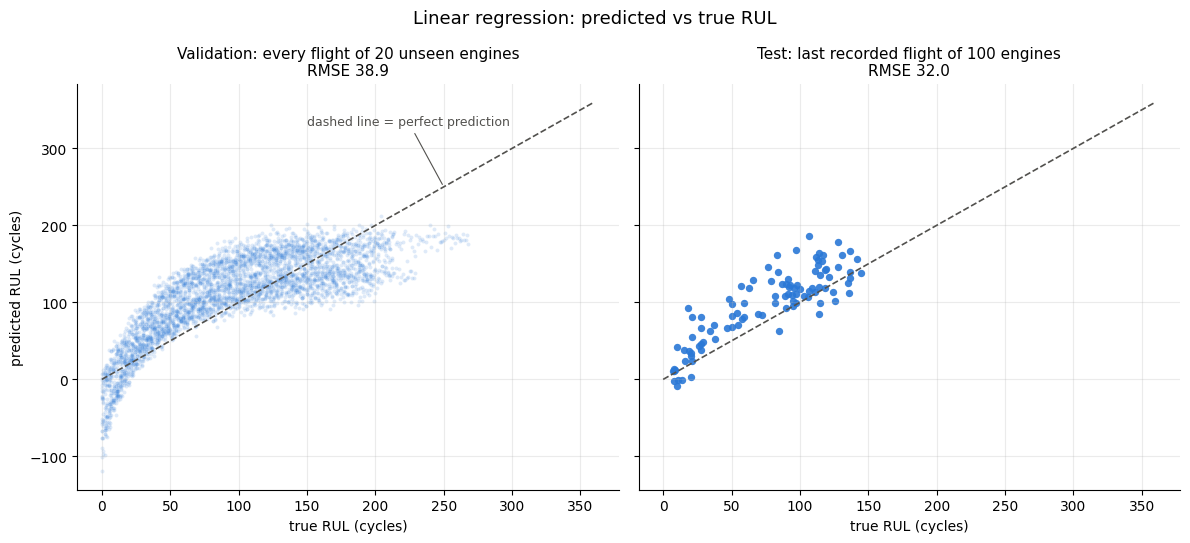

In [8]:
fig = plot_predicted_vs_true(
    [('Validation: every flight of 20 unseen engines', val.RUL, linreg.predict(val[features])),
     ('Test: last recorded flight of 100 engines', test_last.RUL, test_pred)],
    'Linear regression: predicted vs true RUL')

**Result: test RMSE ≈ 32.0**, down from 52.6.

**What the chart shows:** the dots make a curve, because a straight-line model can't follow curved wear. Near failure it predicts impossible negative RUL; for healthy engines it flattens out around 150 to 190 whatever the truth is; and on the test set it guesses too high for most engines, the unsafe direction. Week 3's first fix (clipping RUL at 125) targets exactly this.